<a href="https://colab.research.google.com/github/soumoreira/Projeto_IA/blob/main/Codigo_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔄 O que é Churn? — Introdução com Machine Learning

## Objetivo
Neste notebook você vai aprender:
- O que é **Churn** (cancelamento de clientes)
- Como usar **Machine Learning** para prever quais clientes têm risco de sair
- Como interpretar os resultados de um modelo preditivo

---

### 💡 O que é Churn?
**Churn** é quando um cliente para de usar o seu produto ou serviço — cancela, deixa de comprar, vai para a concorrência.

Exemplos do dia a dia:
- Cliente cancela assinatura de streaming 📺
- Usuário deleta o app e vai para o concorrente 📱
- Cliente encerra conta em banco 🏦
- Assinante cancela plano de internet 📡

**Por que isso importa?** Adquirir um cliente novo custa de 5 a 7x mais do que manter um cliente atual. Prever quem vai sair permite agir antes!


In [ ]:
# ============================================================
# CÉLULA 1 — Importações
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score
)

import warnings
warnings.filterwarnings('ignore')

# Configuração visual
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')
print('✅ Bibliotecas importadas com sucesso!')

✅ Bibliotecas importadas com sucesso!


## 📦 Passo 1 — Criar um Dataset Genérico de Clientes

Vamos simular dados de uma empresa fictícia com clientes de qualquer segmento.

As variáveis que usaremos:
| Variável | Descrição |
|---|---|
| `idade` | Idade do cliente |
| `tempo_cliente` | Meses como cliente |
| `valor_mensal` | Valor pago por mês (R$) |
| `qtd_produtos` | Número de produtos contratados |
| `reclamacoes` | Reclamações no último ano |
| `usa_app` | Usa o aplicativo? (1=Sim, 0=Não) |
| `indicou_amigos` | Indicou amigos? (1=Sim, 0=Não) |
| `atrasos` | Pagamentos em atraso |
| `churn` | **Saiu da empresa?** (1=Sim, 0=Não) — isso é o que queremos prever! |

In [ ]:
# ============================================================
# CÉLULA 2 — Criar dataset sintético
# ============================================================
np.random.seed(42)
n = 1000
# Características dos clientes
idade          = np.random.randint(18, 80, n)
tempo_cliente  = np.random.randint(1, 72, n)
valor_mensal   = np.round(np.random.uniform(50, 250, n), 2)
qtd_produtos   = np.random.randint(1, 6, n)
reclamacoes    = np.random.randint(0, 6, n)
usa_app        = np.random.randint(0, 2, n)
indicou_amigos = np.random.randint(0, 4, n)
atrasos        = np.random.randint(0, 5, n)

# Regra de negócio para gerar churn realista:
# Clientes com mais reclamações, mais atrasos e menos tempo tendem a sair mais
prob_churn = (
    0.03 * reclamacoes +
    0.05 * atrasos -
    0.002 * tempo_cliente -
    0.01 * indicou_amigos -
    0.005 * usa_app +
    np.random.normal(0, 0.1, n)
)
churn = (prob_churn > 0.05).astype(int)

df = pd.DataFrame({
    'idade': idade,
    'tempo_cliente': tempo_cliente,
    'valor_mensal': valor_mensal,
    'qtd_produtos': qtd_produtos,
    'reclamacoes': reclamacoes,
    'usa_app': usa_app,
    'indicou_amigos': indicou_amigos,
    'atrasos': atrasos,
    'churn': churn
})

print(f'Dataset criado com {len(df)} clientes')
print(f'\nDistribuição de Churn:')
print(df['churn'].value_counts())
print(f'\nTaxa de churn: {df["churn"].mean()*100:.1f}%')
df.head(10)

Dataset criado com 1000 clientes

Distribuição de Churn:
churn
1    622
0    378
Name: count, dtype: int64

Taxa de churn: 62.2%


,idade,tempo_cliente,valor_mensal,qtd_produtos,reclamacoes,usa_app,indicou_amigos,atrasos,churn
0,56,11,139.27,4,2,0,2,3,0
1,69,26,222.84,1,3,1,2,0,1
2,46,63,161.63,4,4,1,3,2,1
3,32,59,157.98,1,0,1,3,3,1
4,60,27,56.84,5,3,0,2,0,0
5,25,49,247.34,2,3,1,1,2,1
6,78,33,74.59,5,3,0,3,1,0
7,38,1,96.23,3,2,0,2,1,1
8,56,21,60.34,3,1,1,3,1,0
9,75,55,178.00,3,0,1,2,3,0


## 📊 Passo 2 — Análise Exploratória
Antes de treinar qualquer modelo, precisamos **entender os dados**!

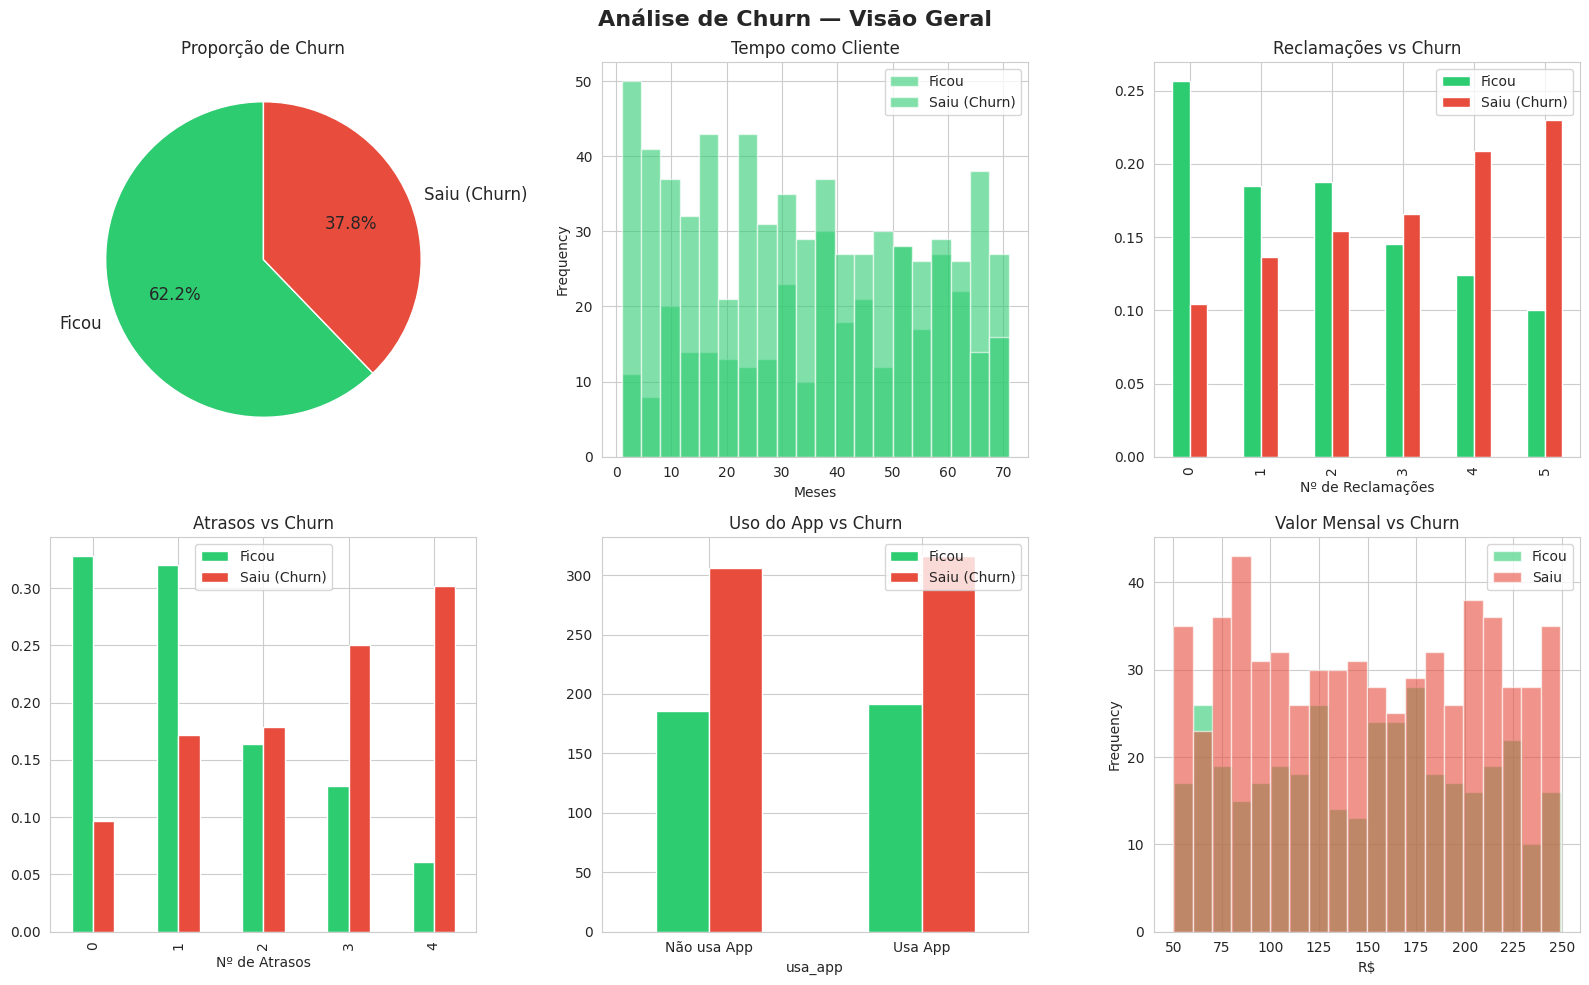

In [ ]:
# ============================================================
# CÉLULA 3 — Visualizações exploratórias
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Análise de Churn — Visão Geral', fontsize=16, fontweight='bold')

cores = ['#2ecc71', '#e74c3c']
labels = ['Ficou', 'Saiu (Churn)']

# 1. Pizza de churn
contagem = df['churn'].value_counts()
axes[0,0].pie(contagem, labels=labels, colors=cores, autopct='%1.1f%%',
              startangle=90, textprops={'fontsize': 12})
axes[0,0].set_title('Proporção de Churn')

# 2. Tempo como cliente
df.groupby('churn')['tempo_cliente'].plot(kind='hist', ax=axes[0,1],
    alpha=0.6, bins=20, color=cores, legend=True)
axes[0,1].set_title('Tempo como Cliente')
axes[0,1].set_xlabel('Meses')
axes[0,1].legend(labels)

# 3. Reclamações
df.groupby('churn')['reclamacoes'].value_counts(normalize=True).unstack(0).plot(
    kind='bar', ax=axes[0,2], color=cores, edgecolor='white')
axes[0,2].set_title('Reclamações vs Churn')
axes[0,2].set_xlabel('Nº de Reclamações')
axes[0,2].legend(labels)

# 4. Atrasos
df.groupby('churn')['atrasos'].value_counts(normalize=True).unstack(0).plot(
    kind='bar', ax=axes[1,0], color=cores, edgecolor='white')
axes[1,0].set_title('Atrasos vs Churn')
axes[1,0].set_xlabel('Nº de Atrasos')
axes[1,0].legend(labels)

# 5. Usa app
df.groupby(['usa_app', 'churn']).size().unstack().plot(
    kind='bar', ax=axes[1,1], color=cores, edgecolor='white')
axes[1,1].set_title('Uso do App vs Churn')
axes[1,1].set_xticklabels(['Não usa App', 'Usa App'], rotation=0)
axes[1,1].legend(labels)

# 6. Valor mensal
df[df['churn']==0]['valor_mensal'].plot(kind='hist', ax=axes[1,2],
    alpha=0.6, bins=20, color=cores[0], label='Ficou')
df[df['churn']==1]['valor_mensal'].plot(kind='hist', ax=axes[1,2],
    alpha=0.6, bins=20, color=cores[1], label='Saiu')
axes[1,2].set_title('Valor Mensal vs Churn')
axes[1,2].set_xlabel('R$')
axes[1,2].legend()

plt.tight_layout()
plt.show()

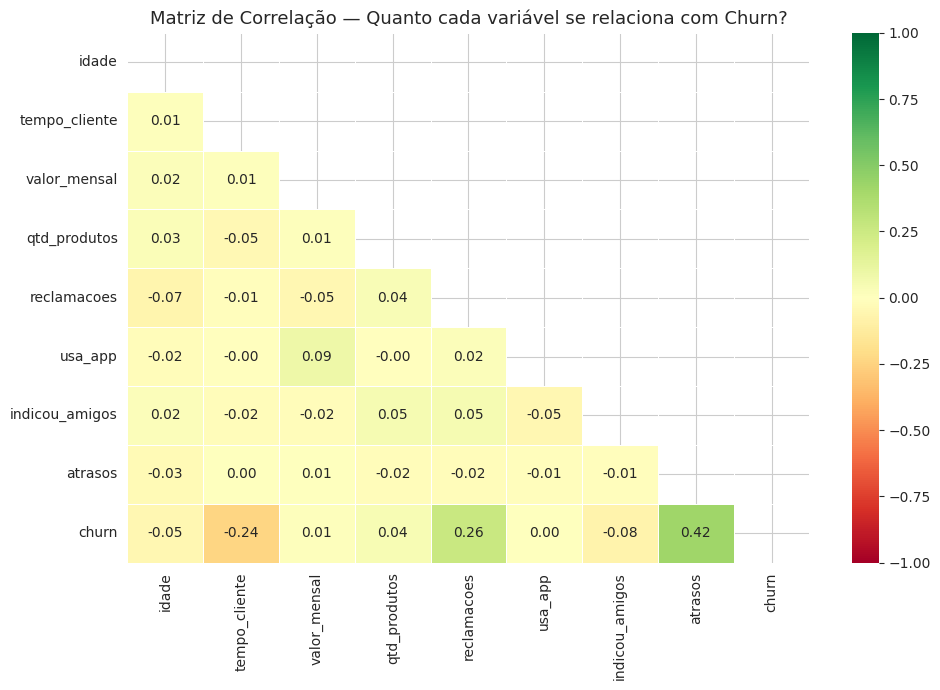


🔍 Correlação direta com Churn:
  🔴 atrasos             : +0.416
  🔴 reclamacoes         : +0.262
  ⚪ qtd_produtos        : +0.044
  ⚪ valor_mensal        : +0.013
  ⚪ usa_app             : +0.000
  ⚪ idade               : -0.047
  🟢 indicou_amigos      : -0.075
  🟢 tempo_cliente       : -0.239


In [ ]:
# ============================================================
# CÉLULA 4 — Correlação entre variáveis
# ============================================================
plt.figure(figsize=(10, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            mask=mask, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação — Quanto cada variável se relaciona com Churn?',
          fontsize=13)
plt.tight_layout()
plt.show()

print('\n🔍 Correlação direta com Churn:')
corr_churn = df.corr()['churn'].drop('churn').sort_values(ascending=False)
for col, val in corr_churn.items():
    sinal = '🔴' if val > 0.05 else ('🟢' if val < -0.05 else '⚪')
    print(f'  {sinal} {col:20s}: {val:+.3f}')

## 🤖 Passo 3 — Treinando o Modelo de Machine Learning

Usaremos dois algoritmos clássicos para prever Churn:

- **Regressão Logística** — simples, interpretável, ideal para entender o impacto de cada variável
- **Random Forest** — mais poderoso, usa várias árvores de decisão em conjunto

> 💬 *O modelo aprende com dados históricos de clientes que já saíram para prever quem pode sair no futuro!*

In [ ]:
# ============================================================
# CÉLULA 5 — Preparação dos dados
# ============================================================
X = df.drop('churn', axis=1)
y = df['churn']

# Divisão treino/teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalização
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'✅ Dados divididos:')
print(f'   Treino: {len(X_train)} amostras')
print(f'   Teste:  {len(X_test)} amostras')

✅ Dados divididos:
   Treino: 800 amostras
   Teste:  200 amostras


In [ ]:
# ============================================================
# CÉLULA 6 — Treinar os dois modelos
# ============================================================

# Regressão Logística
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
acc_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, lr.predict_proba(X_test_sc)[:,1])

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test)[:,1])

print('='*45)
print(f'  Modelo                  | Acurácia | AUC')
print('='*45)
print(f'  Regressão Logística     |  {acc_lr*100:.1f}%   | {auc_lr:.3f}')
print(f'  Random Forest           |  {acc_rf*100:.1f}%   | {auc_rf:.3f}')
print('='*45)

  Modelo                  | Acurácia | AUC
  Regressão Logística     |  79.5%   | 0.860
  Random Forest           |  74.0%   | 0.804


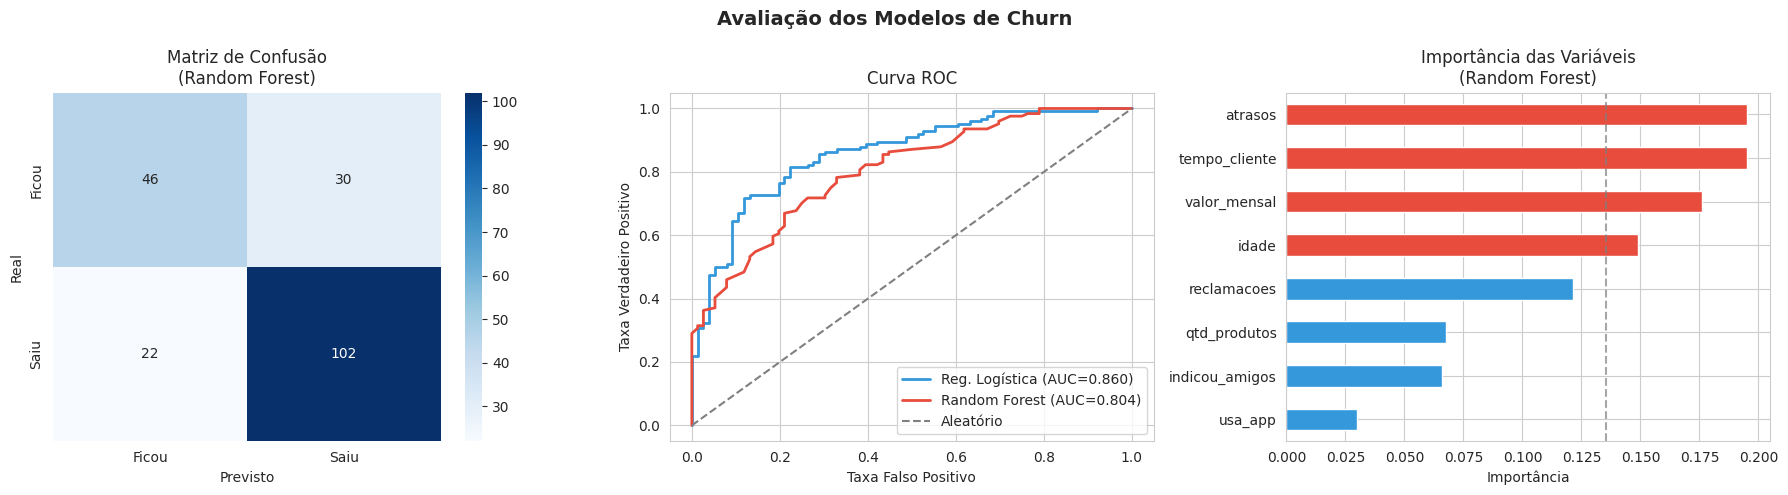

In [ ]:
# ============================================================
# CÉLULA 7 — Visualizar resultados
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Avaliação dos Modelos de Churn', fontsize=14, fontweight='bold')

# Matriz de confusão — Random Forest
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ficou','Saiu'], yticklabels=['Ficou','Saiu'])
axes[0].set_title('Matriz de Confusão\n(Random Forest)')
axes[0].set_xlabel('Previsto')
axes[0].set_ylabel('Real')

# Curva ROC
for modelo, nome, cor in [
    (lr, 'Reg. Logística', '#3498db'),
    (rf, 'Random Forest',  '#e74c3c')
]:
    X_t = X_test_sc if modelo == lr else X_test
    fpr, tpr, _ = roc_curve(y_test, modelo.predict_proba(X_t)[:,1])
    auc = roc_auc_score(y_test, modelo.predict_proba(X_t)[:,1])
    axes[1].plot(fpr, tpr, label=f'{nome} (AUC={auc:.3f})', color=cor, lw=2)
axes[1].plot([0,1],[0,1],'--', color='gray', label='Aleatório')
axes[1].set_title('Curva ROC')
axes[1].set_xlabel('Taxa Falso Positivo')
axes[1].set_ylabel('Taxa Verdadeiro Positivo')
axes[1].legend()
axes[1].grid(True)

# Importância das variáveis
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
.sort_values(ascending=True)
cores_barras = ['#e74c3c' if v > feat_imp.median()
else '#3498db' for v in feat_imp]
feat_imp.plot(kind='barh', ax=axes[2], color=cores_barras, edgecolor='white')
axes[2].set_title('Importância das Variáveis\n(Random Forest)')
axes[2].set_xlabel('Importância')
axes[2].axvline(feat_imp.median(), color='gray', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 🎯 Passo 4 — Usando o Modelo na Prática

Agora vamos simular o uso real: **dado um novo cliente, qual a probabilidade de ele cancelar?**

🚨 CLIENTE COM ALTO RISCO:
  RESULTADO DA ANÁLISE DE CHURN
  Probabilidade de Churn: 94.0%
  Nível de Risco: 🔴 ALTO


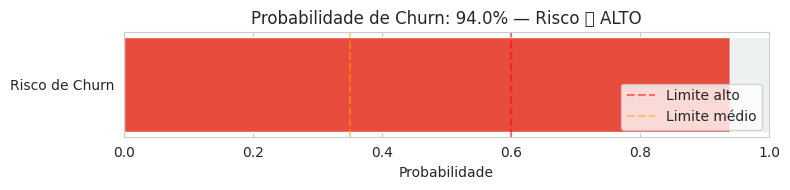

In [ ]:
# ============================================================
# CÉLULA 8 — Prever risco de churn de um novo cliente
# ============================================================

def prever_churn_cliente(idade, tempo_cliente, valor_mensal, qtd_produtos,
                          reclamacoes, usa_app, indicou_amigos, atrasos):
    """
    Retorna a probabilidade de churn de um cliente específico.
    """
    cliente = pd.DataFrame([{
        'idade': idade,
        'tempo_cliente': tempo_cliente,
        'valor_mensal': valor_mensal,
        'qtd_produtos': qtd_produtos,
        'reclamacoes': reclamacoes,
        'usa_app': usa_app,
        'indicou_amigos': indicou_amigos,
        'atrasos': atrasos
    }])

    prob = rf.predict_proba(cliente)[0][1]
    risco = '🔴 ALTO' if prob > 0.6 else ('🟡 MÉDIO' if prob > 0.35
                                          else '🟢 BAIXO')

    print('='*50)
    print(f'  RESULTADO DA ANÁLISE DE CHURN')
    print('='*50)
    print(f'  Probabilidade de Churn: {prob*100:.1f}%')
    print(f'  Nível de Risco: {risco}')
    print('='*50)

    # Gráfico de risco
    fig, ax = plt.subplots(figsize=(8, 2))
    cor = '#e74c3c' if prob > 0.6 else ('#f39c12' if prob > 0.35 else '#2ecc71')
    ax.barh(['Risco de Churn'], [prob], color=cor, height=0.4)
    ax.barh(['Risco de Churn'], [1 - prob], left=[prob], color='#ecf0f1',
            height=0.4)
    ax.set_xlim(0, 1)
    ax.axvline(0.6, color='red', linestyle='--', alpha=0.5, label='Limite alto')
    ax.axvline(0.35, color='orange', linestyle='--', alpha=0.5,
               label='Limite médio')
    ax.set_xlabel('Probabilidade')
    ax.set_title(f'Probabilidade de Churn: {prob*100:.1f}% — Risco {risco}')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# ----- TESTE 1: Cliente com alto risco -----
print('🚨 CLIENTE COM ALTO RISCO:')
prever_churn_cliente(
    idade=32, tempo_cliente=5, valor_mensal=220,
    qtd_produtos=1, reclamacoes=4, usa_app=0,
    indicou_amigos=0, atrasos=3
)

In [ ]:
# ----- TESTE 2: Cliente fiel -----
print('✅ CLIENTE FIEL (BAIXO RISCO):')
prever_churn_cliente(
    idade=45, tempo_cliente=60, valor_mensal=150,
    qtd_produtos=3, reclamacoes=0, usa_app=1,
    indicou_amigos=3, atrasos=0
)

## 📋 Relatório Final — Clientes em Risco

In [ ]:
# ============================================================
# CÉLULA 9 — Lista de clientes em risco
# ============================================================
df_test = X_test.copy()
df_test['churn_real']     = y_test.values
df_test['prob_churn']     = rf.predict_proba(X_test)[:,1]
df_test['risco']          = df_test['prob_churn'].apply(
    lambda p: 'ALTO' if p > 0.6 else ('MÉDIO' if p > 0.35 else 'BAIXO')
)

# Top 10 clientes com maior risco
top_risco = df_test.nlargest(10, 'prob_churn')[[
    'idade', 'tempo_cliente', 'reclamacoes', 'atrasos', 'prob_churn', 'risco'
]].reset_index(drop=True)
top_risco.index += 1
top_risco['prob_churn'] = (top_risco['prob_churn'] * 100).round(1).astype(str)
+ '%'

print('🚨 TOP 10 CLIENTES COM MAIOR RISCO DE CHURN:')
print(top_risco.to_string())

print('\n📊 Resumo por nível de risco:')
print(df_test['risco'].value_counts())

🚨 TOP 10 CLIENTES COM MAIOR RISCO DE CHURN:
    idade  tempo_cliente  reclamacoes  atrasos prob_churn risco
1      40             23            5        4      99.0%  ALTO
2      70             12            4        4      97.0%  ALTO
3      30             15            4        3      97.0%  ALTO
4      38             20            4        4      97.0%  ALTO
5      62             44            4        3      96.0%  ALTO
6      43             12            5        3      95.0%  ALTO
7      42             18            5        3      95.0%  ALTO
8      52             24            5        3      95.0%  ALTO
9      45              9            5        3      93.0%  ALTO
10     41              3            5        4      93.0%  ALTO

📊 Resumo por nível de risco:
risco
ALTO     106
MÉDIO     61
BAIXO     33
Name: count, dtype: int64


---
## 🤔 Reflexão Final

Responda as questões abaixo no caderno ou em um documento:

1. **Qual variável teve maior impacto no churn?** O que isso significa para a empresa?
2. **Por que dividimos os dados em treino e teste?** O que aconteceria se treinássemos e testássemos com os mesmos dados?
3. **O que é a Curva ROC?** Por que ela é mais útil que a acurácia sozinha?
4. **Se você fosse gerente de clientes**, quais ações tomaria para os clientes de risco ALTO?
5. **Qual a diferença entre Regressão Logística e Random Forest?** Em que situações cada um seria mais útil?

---
### 🚀 Próximo Passo
No próximo notebook, vamos usar **dados reais de uma empresa de telecomunicações** para prever churn com informações mais ricas e complexas!
